# Spatial information of putative mitral and tufted cells

Do putative mitral, tufted or `other` OB units (`mt_cell_inventory.csv`, from `mt_classifier.py`) more often carry
significant spatial information, and are the three types drawn evenly from the mice?

Spatial significance comes from two existing scores, each for the search and the retrieval epoch:

- **SSI** (`spatial_info.py`): Skaggs SI against circular spike-time shifts (`ssi`, `p_empirical`)
- **SI per second** and **SI per sniff** (`sniff_rate_map.py`): `si_rate_z/p` is the usual rate map; `si_sniff_z/p`
  divides it by the sniff-rate map, so a unit does not look spatial just because the animal sniffs faster in some places
  of the arena. Tufted units are by construction the most sniff-locked, so SI per sniff is the fairest comparison.

A unit is spatially significant if p < 0.05. The types differ between mice, and spike count sets how easily a unit
reaches significance, so the comparisons are repeated within mouse and adjusted for spike count.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

ALPHA = 0.05
SNIFF = 'E:/cbm-odor/sniff/'
EPOCHS = ['search', 'retrieval']
MEASURES = {'SSI': ('ssi', 'p_empirical'), 'SI per second': ('si_rate_z', 'si_rate_p'),
            'SI per sniff': ('si_sniff_z', 'si_sniff_p')}
TYPES = ['tufted', 'mitral', 'other']
colors = {'tufted': 'tab:blue', 'mitral': 'tab:red', 'other': 'tab:gray'}
keys = ['mouse', 'session', 'region', 'cluster']

inv = pd.read_csv(SNIFF + 'mt_cell_inventory.csv', dtype={'mouse': str})
inv['session_id'] = inv['mouse'] + '/' + inv['session']
frames = []
for e in EPOCHS:
    si = pd.read_csv(SNIFF + f'spatial_info_{e}.csv', dtype={'mouse': str})
    sr = pd.read_csv(SNIFF + f'sniff_rate_map_{e}.csv', dtype={'mouse': str})
    d = (inv.merge(si[keys + ['ssi', 'p_empirical']], on=keys, how='left')
            .merge(sr[keys + ['n_spikes', 'si_rate_z', 'si_rate_p', 'si_sniff_z', 'si_sniff_p']], on=keys, how='left'))
    frames.append(d.assign(epoch=e))
df = pd.concat(frames, ignore_index=True)
df['log_spikes'] = np.log10(df['n_spikes'])
print(f"{len(inv)} units; SSI missing for {df.loc[df['epoch'] == 'search', 'ssi'].isna().sum()} "
      '(sessions not in spatial_info_search.csv)')

1968 units; SSI missing for 0 (sessions not in spatial_info_search.csv)


## Which mice the types come from

Counts and row proportions per mouse, with a chi-square test of independence between mouse and type.

In [2]:
counts = pd.crosstab(inv['mouse'], inv['cell_type'])[TYPES]
chi2, p, dof, _ = stats.chi2_contingency(counts)
cramer_v = np.sqrt(chi2 / (counts.to_numpy().sum() * (min(counts.shape) - 1)))
print(f'mouse x type: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2g}, Cramer V = {cramer_v:.2f}')
summary = counts.copy()
summary['units'] = counts.sum(1)
summary['sessions'] = inv.groupby('mouse')['session'].nunique()
summary[[f'{t} %' for t in TYPES]] = (100 * counts.div(counts.sum(1), axis=0)).round(0)
summary

mouse x type: chi2 = 614.4, dof = 14, p = 4.6e-122, Cramer V = 0.40


cell_type,tufted,mitral,other,units,sessions,tufted %,mitral %,other %
mouse,,,,,,,,
9000,46,97,96,239,17,19.0,41.0,40.0
9002,13,84,132,229,17,6.0,37.0,58.0
9003,107,10,53,170,12,63.0,6.0,31.0
9005,139,89,52,280,18,50.0,32.0,19.0
9006,53,191,215,459,16,12.0,42.0,47.0
9007,71,11,52,134,12,53.0,8.0,39.0
9008,111,90,65,266,16,42.0,34.0,24.0
9009,167,11,13,191,11,87.0,6.0,7.0


Left: type proportions per mouse. Right: fraction tufted in each session, to see whether a mouse's mix is
stable across its sessions (a property of the recording site) or varies from day to day.

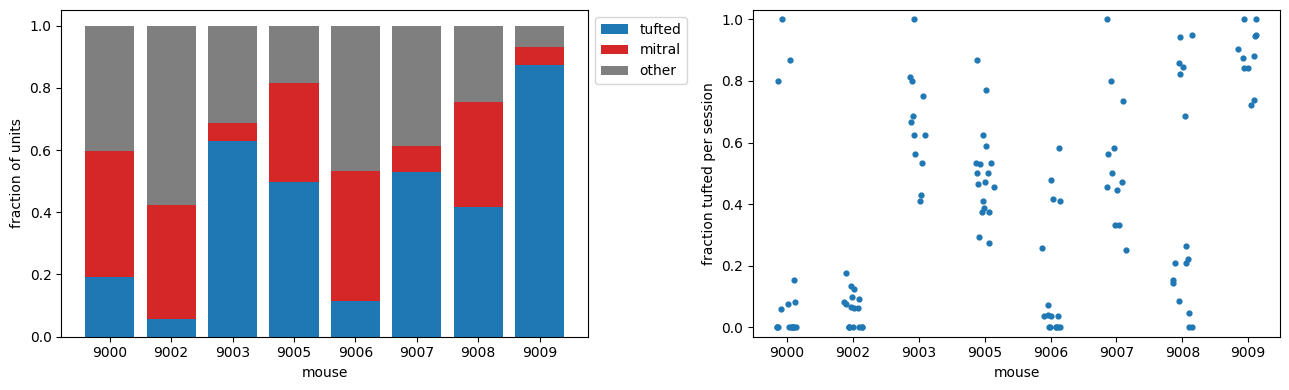

In [3]:
frac = counts.div(counts.sum(1), axis=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bottom = np.zeros(len(frac))
for t in TYPES:
    ax[0].bar(frac.index, frac[t], bottom=bottom, color=colors[t], label=t)
    bottom += frac[t].to_numpy()
ax[0].set(ylabel='fraction of units', xlabel='mouse')
ax[0].legend(loc='upper left', bbox_to_anchor=(1, 1))
per_sess = inv.groupby(['mouse', 'session'])['cell_type'].apply(lambda s: (s == 'tufted').mean()).reset_index(name='f')
mice = sorted(inv['mouse'].unique())
for i, m in enumerate(mice):
    f = per_sess.loc[per_sess['mouse'] == m, 'f']
    ax[1].scatter(i + np.random.default_rng(i).uniform(-0.15, 0.15, len(f)), f, s=12, c=colors['tufted'])
ax[1].set_xticks(range(len(mice)), mice)
ax[1].set(ylabel='fraction tufted per session', xlabel='mouse', ylim=(-0.03, 1.03))
plt.tight_layout()

## Spatial significance by type, pooled

Fraction of units with p < 0.05 and median z per type. `chi2 p` tests type x significant; `KW p` is a Kruskal-Wallis
test of the z-scores across the three types. Pooled over mice, so read it with the mouse table above in mind.

In [4]:
rows = []
for e in EPOCHS:
    d = df[df['epoch'] == e]
    for name, (z, p) in MEASURES.items():
        dd = d.dropna(subset=[z, p])
        sig = dd[p] < ALPHA
        tab = pd.crosstab(dd['cell_type'], sig)
        row = dict(epoch=e, measure=name, n=len(dd),
                   chi2_p=stats.chi2_contingency(tab)[1],
                   KW_p=stats.kruskal(*[dd.loc[dd['cell_type'] == t, z] for t in TYPES]).pvalue)
        for t in TYPES:
            s = dd['cell_type'] == t
            row[f'{t} sig %'] = 100 * sig[s].mean()
            row[f'{t} median z'] = dd.loc[s, z].median()
        rows.append(row)
pooled = pd.DataFrame(rows).set_index(['epoch', 'measure'])
pooled.style.format({c: '{:.2g}' for c in ['chi2_p', 'KW_p']} | {c: '{:.1f}' for c in pooled.columns if '%' in c or 'median' in c})

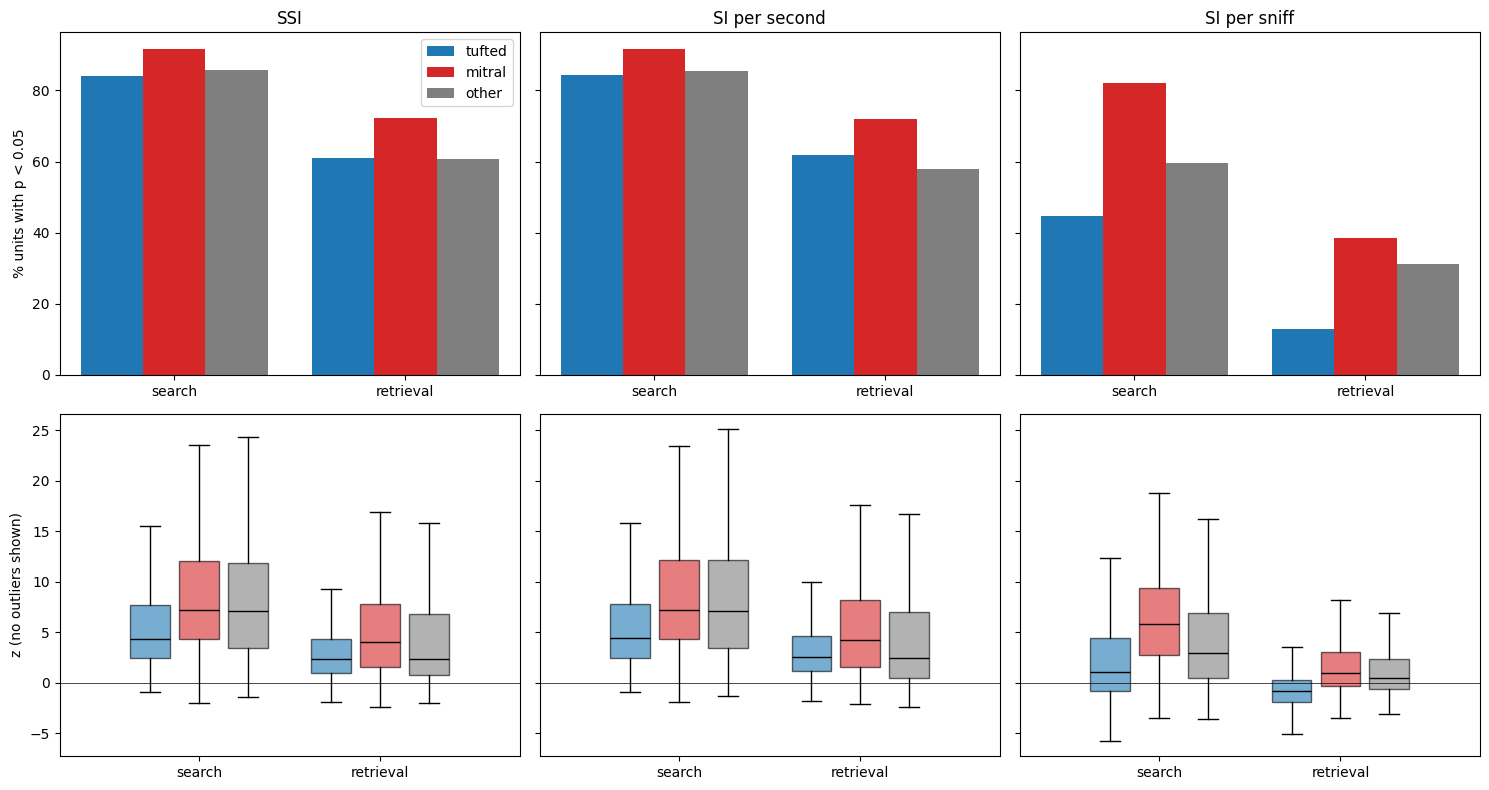

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8), sharey='row')
x = np.arange(len(EPOCHS))
for j, (name, (z, p)) in enumerate(MEASURES.items()):
    for k, t in enumerate(TYPES):
        ax[0, j].bar(x + (k - 1) * 0.27, [pooled.loc[(e, name), f'{t} sig %'] for e in EPOCHS], 0.27,
                     color=colors[t], label=t)
        d = df[df['cell_type'] == t]
        ax[1, j].boxplot([d.loc[d['epoch'] == e, z].dropna() for e in EPOCHS], positions=x + (k - 1) * 0.27,
                         widths=0.22, showfliers=False, patch_artist=True,
                         boxprops=dict(facecolor=colors[t], alpha=0.6), medianprops=dict(color='k'))
    ax[0, j].set(title=name, xticks=x, xticklabels=EPOCHS)
    ax[1, j].set(xticks=x, xticklabels=EPOCHS)
    ax[1, j].axhline(0, c='k', lw=0.5)
ax[0, 0].set_ylabel(f'% units with p < {ALPHA}')
ax[1, 0].set_ylabel('z (no outliers shown)')
ax[0, 0].legend()
plt.tight_layout()

## Within mouse

Each line is one mouse: the fraction of its units of each type that are spatially significant (types with fewer than
10 units in a mouse are left out). If a type difference is real, it should show up within most mice, not only
between mice with different type mixes.

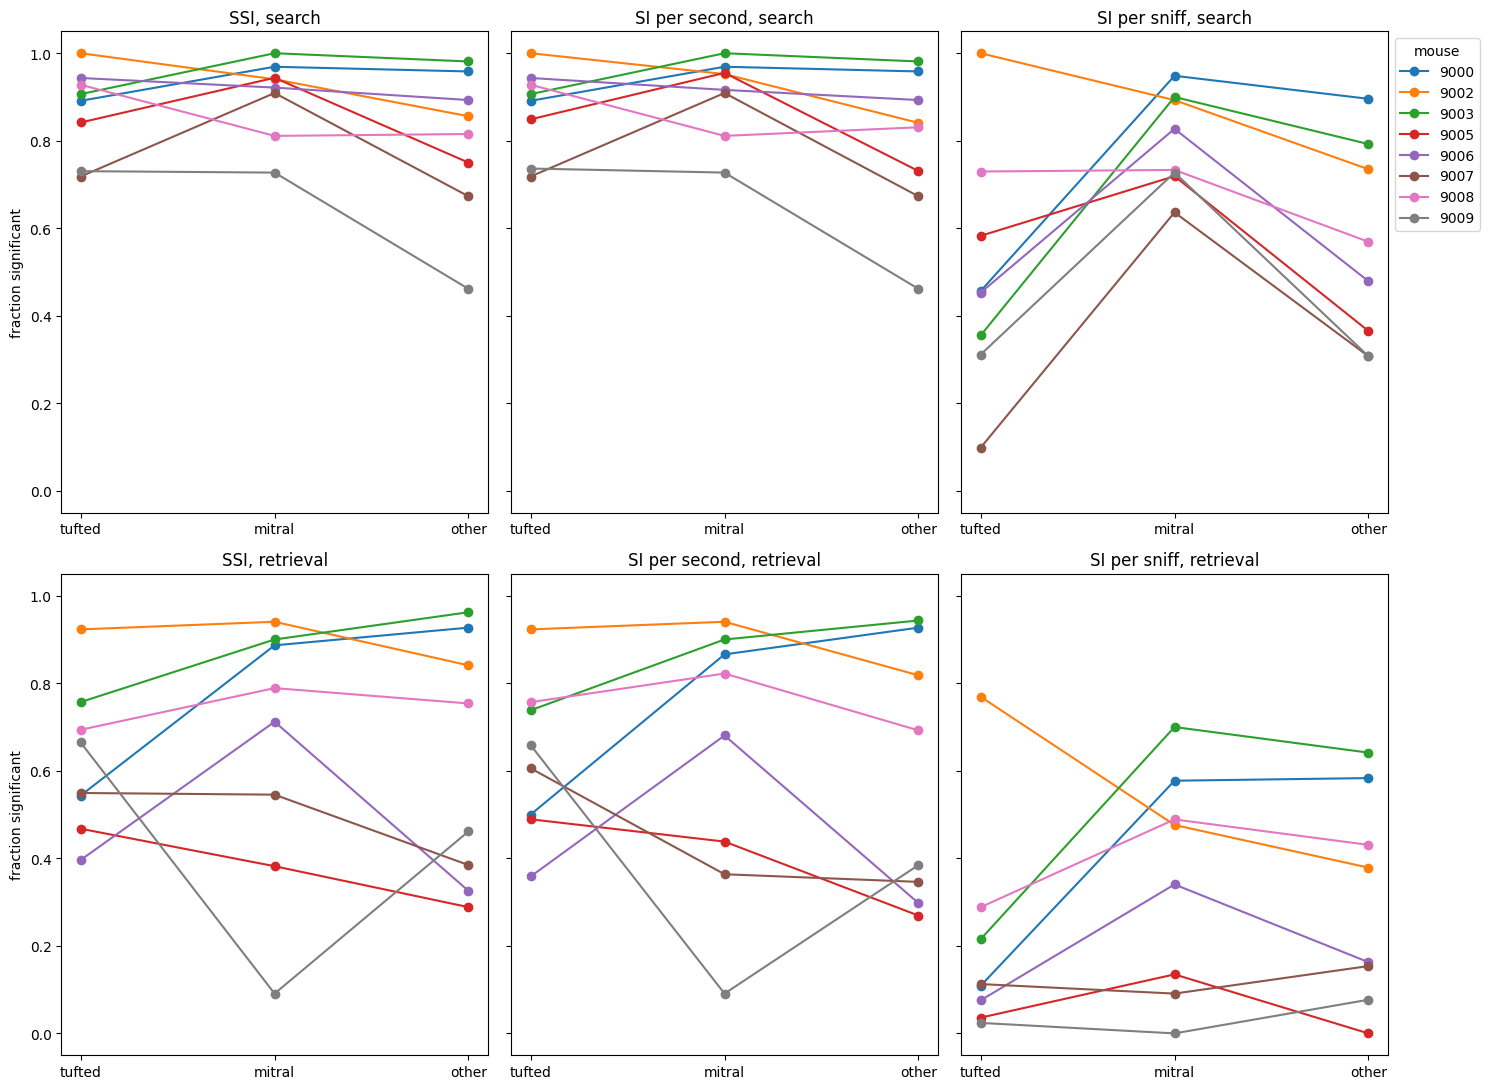

In [6]:
MIN_UNITS = 10
fig, ax = plt.subplots(len(EPOCHS), 3, figsize=(15, 11), sharey=True)
for i, e in enumerate(EPOCHS):
    for j, (name, (z, p)) in enumerate(MEASURES.items()):
        d = df[(df['epoch'] == e)].dropna(subset=[p])
        g = d.groupby(['mouse', 'cell_type'])[p].agg(frac=lambda s: (s < ALPHA).mean(), n='size').reset_index()
        g = g[g['n'] >= MIN_UNITS]
        for m, gm in g.groupby('mouse'):
            gm = gm.set_index('cell_type').reindex(TYPES)
            ax[i, j].plot(range(3), gm['frac'], marker='o', label=m)
        ax[i, j].set(xticks=range(3), xticklabels=TYPES, title=f'{name}, {e}')
    ax[i, 0].set_ylabel('fraction significant')
ax[0, 2].legend(title='mouse', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()

## Adjusted for mouse and spike count

Logistic regression of spatial significance on type, with a fixed effect per mouse and log10 spike count as a
covariate; standard errors are clustered by session (units of a session share its behavior). Tufted is the reference,
so each row gives the odds ratio of being spatially significant for mitral or other units relative to tufted units in
the same mouse with the same spike count. The same model with z as the outcome (OLS) gives the difference in z.

In [7]:
rows = []
for e in EPOCHS:
    for name, (z, p) in MEASURES.items():
        d = df[df['epoch'] == e].dropna(subset=[z, p, 'log_spikes']).copy()
        d['sig'] = (d[p] < ALPHA).astype(int)
        groups = d['session_id'].astype('category').cat.codes
        f = "C(cell_type, Treatment('tufted')) + C(mouse) + log_spikes"
        logit = smf.logit(f'sig ~ {f}', d).fit(disp=0, cov_type='cluster', cov_kwds=dict(groups=groups))
        ols = smf.ols(f'{z} ~ {f}', d).fit(cov_type='cluster', cov_kwds=dict(groups=groups))
        for t in ('mitral', 'other'):
            term = f"C(cell_type, Treatment('tufted'))[T.{t}]"
            lo, hi = np.exp(logit.conf_int().loc[term])
            rows.append(dict(epoch=e, measure=name, vs_tufted=t, odds_ratio=np.exp(logit.params[term]),
                             or_ci=f'{lo:.2f}-{hi:.2f}', logit_p=logit.pvalues[term],
                             z_difference=ols.params[term], ols_p=ols.pvalues[term]))
adjusted = pd.DataFrame(rows).set_index(['epoch', 'measure', 'vs_tufted'])
adjusted.style.format({'odds_ratio': '{:.2f}', 'z_difference': '{:.2f}', 'logit_p': '{:.2g}', 'ols_p': '{:.2g}'})

## Other, split by reason

`other` mixes units that are not sniff-locked with locked units the classifier could not call. Pooled fraction
significant for each.

In [8]:
d = df.copy()
d['group'] = np.where(d['cell_type'] == 'other', d['other_reason'], d['cell_type'])
d = d[d['group'] != 'few_spikes']
out = {}
for name, (z, p) in MEASURES.items():
    out[name] = d.dropna(subset=[p]).groupby(['epoch', 'group'])[p].apply(lambda s: 100 * (s < ALPHA).mean()).unstack()
pd.concat(out, axis=1).round(1)

SSI                          SI per second                    \
group     ambiguous mitral not_locked tufted     ambiguous mitral not_locked   
epoch                                                                          
retrieval      66.0   72.4       59.9   61.0          64.9   72.0       57.1   
search         83.5   91.6       86.5   84.0          84.5   91.8       85.9   

                 SI per sniff                           
group     tufted    ambiguous mitral not_locked tufted  
epoch                                                   
retrieval   62.0         39.2   38.6       30.0   12.9  
search      84.3         63.9   82.2       58.9   44.8

## Summary (rerun of Nov 23, 2026: search-only M/T labels)

The M/T labels now come from search sniffs only, which moved many units: 583 mitral, 707 tufted and 678 other, against
349, 897 and 722 before.

- **Mice:** the types are far from uniform across mice (chi2 p ~ 1e-121, Cramer V = 0.40). Mitral units come mostly
  from 9000, 9002, 9005, 9006 and 9008 (10-11 units each in 9003, 9007 and 9009). 9009 is 87% tufted, while 9002 and
  9006 are only 6% and 12% tufted. Within a mouse the mix still varies from session to session (from 0 to nearly all
  tufted in 9000 and 9008), consistent with the tetrodes being advanced between sessions.
- **SSI and SI per second:** in search, 84-92% of units of every type are significant. After the mouse and spike-count
  adjustment, mitral units are not more often significant than tufted ones in search (odds ratio 1.3, p ~ 0.3), though
  their z is higher (+1.6, p < 0.01). In retrieval (58-72% significant) their odds are higher (odds ratio 1.7-1.9,
  p = 0.02-0.04).
- **SI per sniff:** mitral units are much more often significant than tufted ones (pooled 82% vs 45% in search, 39% vs
  13% in retrieval), and the difference survives the mouse and spike-count adjustment in both epochs (odds ratio about
  3.9, p < 0.001). Tufted units are the most sniff-locked, so more of their apparent spatial tuning is explained by
  where the animal sniffs fast. `other` units sit in between: in search their odds of significance do not differ from
  tufted after adjustment (p = 0.26), only their z (+1.8); in retrieval their odds are higher too (odds ratio 2.5).
- **Within mouse (SI per sniff, search):** mitral units beat tufted ones by more than 10 points in 6 of 8 mice. 9008
  shows no difference, and 9002, which has only 13 tufted units, goes the other way. In retrieval, 5 of 8 mice go the
  pooled way.